In [1]:
from astropy.io import fits
from astropy.wcs import WCS
import astropy
from astropy.coordinates import SkyCoord 
from astropy.wcs.utils import skycoord_to_pixel
from astropy.wcs.utils import pixel_to_skycoord
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
plt.rcParams.update({'font.size': 12})
plt.style.use('seaborn-dark-palette')

from os import listdir
from os.path import isfile, join
from datetime import datetime
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore', category=UserWarning, append=True)
warnings.filterwarnings("ignore", category=astropy.wcs.FITSFixedWarning)

import ta_func_2022 as ta

# How to choose your Aperture sizes

For aperture photometry, there are three radii you need to choose. Lets call them $R_{aperture}$, $R_{inner}$, $R_{outer}$. The purpose of $R_{aperture}$ is to encompass as much of the starlight as possible but not be so big as to add additional noise to the measurments. The purpose of $R_{inner}$ and $R_{outer}$ is to define a localized region around the star that measures estimate the local background flux, $F_{bg}$.

The proper way to choose these values is by formulating and maximizing the signal-to-noise ratio. For this lab, it should be sufficient to choose an aperture and annulus size such that $R_{aperture}$ is roughly three ot four times the radius of the point spread function (where the radius is the standard deviation of a best-fit Gaussian). There aren't many stars nearby the reference stars, so there is a lot of freedom on the size of the annulus.

Let's see an example of how to compute the flux of a simulated star


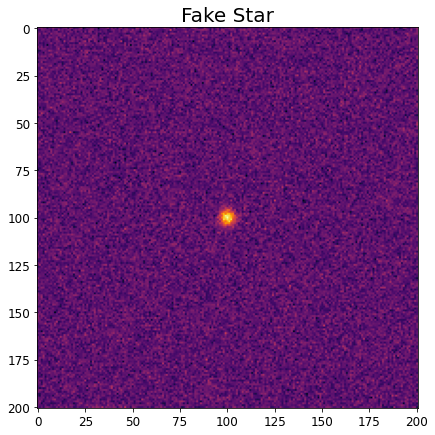

[102.4798546   99.95520069   3.03640601  19.18266449]


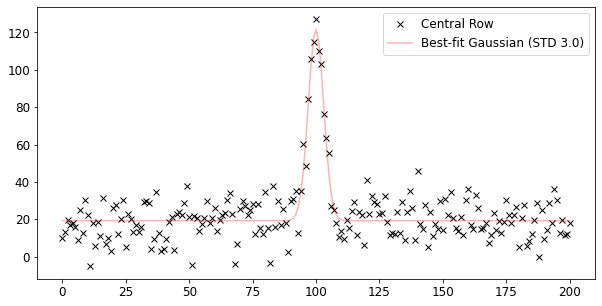

In [2]:
def two_d_gaussian(x,y,ux,uy,sx,sy,A):
    return A*np.exp(-1*((x-ux)**2/(2*sx**2) + (y-uy)**2/(2*sy**2)))

def gaus(x,a,x0,sigma, c):
    return a*np.exp(-(x-x0)**2/(2*sigma**2)) + c

def fake_star(amplitude, noise):
    axis = np.arange(-100,101).astype(float)
    x,y = np.meshgrid(axis,axis)
    
    data = np.zeros_like(x)

    data += two_d_gaussian(x,y,0,0,3,3,amplitude)
    
    return data + np.random.normal(0, noise, x.shape) + 20

amp = 100
star = fake_star(amp, 10)
plt.figure(figsize=(7,7))
plt.imshow(star, cmap = 'inferno')
plt.title("Fake Star", size = 20)
plt.show()

#Now we can fit a Gaussian to the star image
x, y = np.arange(star.shape[0]), star[star.shape[0]//2,:]
popt, pcov = curve_fit(gaus,
                       x,y,
                       p0=[amp,star.shape[0]//2,10, 0])
print(popt)
plt.figure(figsize=(10,5))
plt.plot(x,y, 'x', color = 'k', label = 'Central Row')
plt.plot(x,gaus(x,*popt),color = 'r', alpha = 0.3, label = f'Best-fit Gaussian (STD {round(popt[2],1)})')
plt.legend()
plt.show()

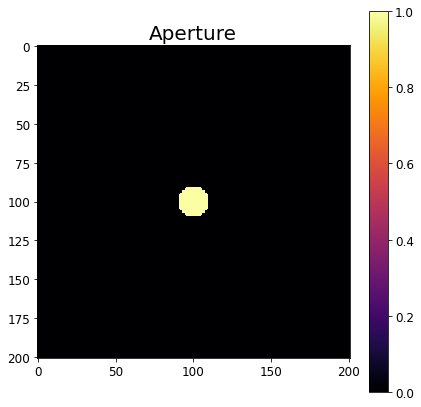

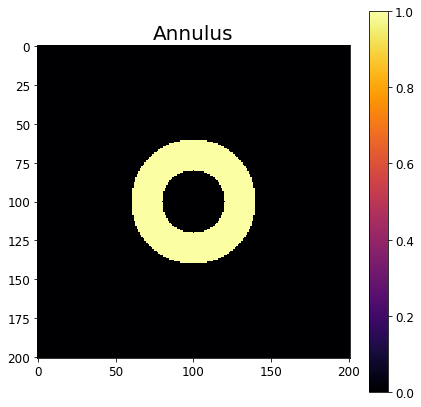

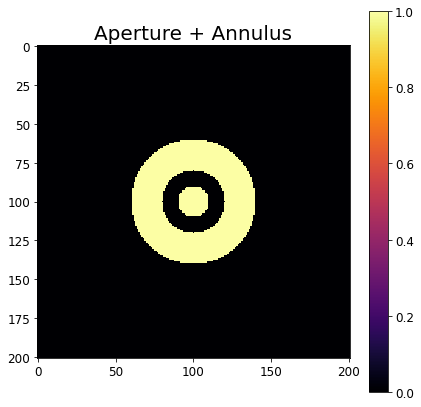

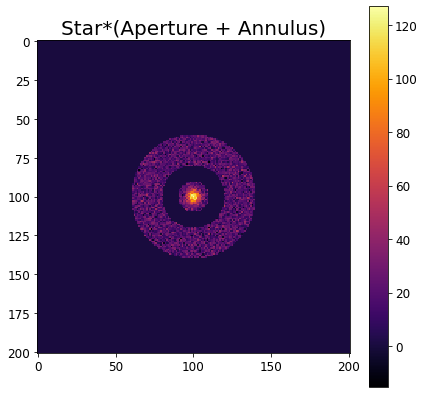

In [3]:
#The easiest way to compute flux is to generate binary masks for the aperture and annulus
aperture = ta.get_aperture(star.shape, 10)
annulus = ta.get_annulus(star.shape, 20, 40)

plt.figure(figsize=(7,7))
plt.imshow(aperture, cmap = 'inferno',interpolation = "None")
plt.title("Aperture", size = 20)
plt.colorbar()
plt.show()

plt.figure(figsize=(7,7))
plt.imshow(annulus, cmap = 'inferno',interpolation = "None")
plt.title("Annulus", size = 20)
plt.colorbar()
plt.show()

plt.figure(figsize=(7,7))
plt.imshow(annulus + aperture, cmap = 'inferno',interpolation = "None")
plt.title("Aperture + Annulus", size = 20)
plt.colorbar()
plt.show()

plt.figure(figsize=(7,7))
plt.imshow(star*(annulus + aperture), cmap = 'inferno',interpolation = "None")
plt.title("Star*(Aperture + Annulus)", size = 20)
plt.colorbar()
plt.show()

# Let's looks how we can compute flux

The total flux, $F_{star}$ is the sum of all of the pixels in the aperture minus the contribution from the background. We can use the annulus pixels to estimate the local background intensity:

$$I_{bg} = \sum_{annulus} \frac{I(x,y)}{N_{annulus}}$$

where $N_{annulus}$ is the number of pixels in the annulus. Now we can estimate the star flux:

$$F_{star} = \sum_{aperture}( I(x,y) - I_{bg})$$

For our example in python we have:

In [4]:
N = annulus[annulus>0].size
bg = np.sum(star*annulus)/N
flux = np.sum((star- bg)*aperture)

print(flux, bg)

5528.774601573697 20.126541224241432


# Now we can looking at the lab data

In [5]:
#get all of the files 
img_files = [f for f in listdir('.') if isfile(join('.', f)) and 'fits' in f]

file_times = []
for f in img_files:
    header = fits.open(f)[0].header
    dt = datetime.fromisoformat(header["DATE-OBS"])
    file_times.append(dt)

#sort files by the same way
file_times, img_files = zip(*sorted(zip(file_times, img_files)))

img_files = np.array(img_files)
file_times = np.array(file_times)

print(img_files[:10])
print(file_times[:10])

['AST325-326-SN-20150920.9181.fits' 'AST325-326-SN-20150920.9361.fits'
 'AST325-326-SN-20150920.9535.fits' 'AST325-326-SN-20150922.1458.fits'
 'AST325-326-SN-20150922.1618.fits' 'AST325-326-SN-20150922.1757.fits'
 'AST325-326-SN-20150922.1924.fits' 'AST325-326-SN-20150922.2083.fits'
 'AST325-326-SN-20150922.2243.fits' 'AST325-326-SN-20150922.2410.fits']
[datetime.datetime(2015, 9, 20, 22, 2, 14)
 datetime.datetime(2015, 9, 20, 22, 28, 10)
 datetime.datetime(2015, 9, 20, 22, 53, 57)
 datetime.datetime(2015, 9, 22, 3, 30, 17)
 datetime.datetime(2015, 9, 22, 3, 53, 5)
 datetime.datetime(2015, 9, 22, 4, 13, 38)
 datetime.datetime(2015, 9, 22, 4, 37, 45)
 datetime.datetime(2015, 9, 22, 5, 0, 6)
 datetime.datetime(2015, 9, 22, 5, 23, 39)
 datetime.datetime(2015, 9, 22, 5, 47, 5)]


[<SkyCoord (ICRS): (ra, dec) in deg
    (14.20708333, -37.02730833)>, <SkyCoord (ICRS): (ra, dec) in deg
    (14.19345833, -37.04152778)>, <SkyCoord (ICRS): (ra, dec) in deg
    (14.24279167, -36.97127778)>]


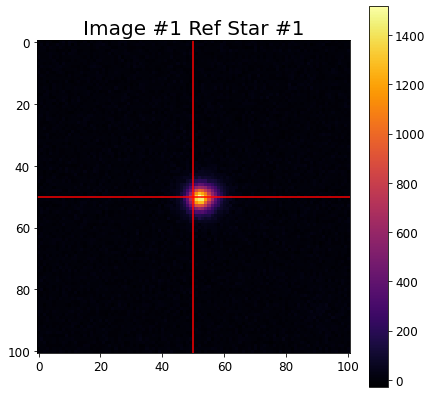

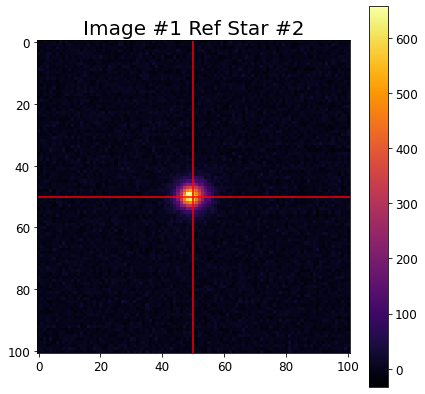

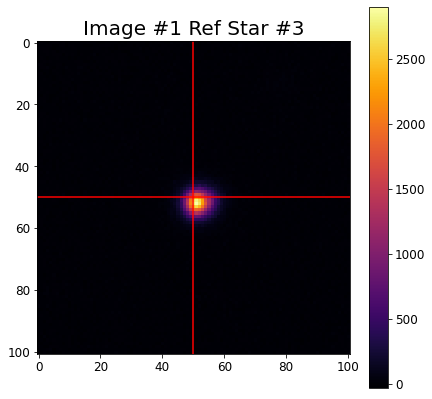

In [6]:
#I put the reference star positions from the lab into Sky Coordinate objects in astropy
print(ta.ref_stars) 

boxsize = 50

#To start, lets loops through each image and read it (we will only do the first few)
#For image in images 
for i, f in enumerate(img_files[:1]):
    
    # read the image
    data, header  = ta.read_file(f)
    # use the fits header information for cordinate transformations
    w = WCS(header)
    
#In each image, we want to find the position of each star
    for j, star in enumerate(ta.ref_stars):
        
        # locate the star
        ref_pos = skycoord_to_pixel(star, w)
        ref_x, ref_y = ref_pos
        
        # we can then put look at a box around the star to set up our flux code above
        ref_x_int, ref_y_int = ref_x.astype(int), ref_y.astype(int)

        #generate region around star
        sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, 
                      ref_x_int-boxsize: ref_x_int+boxsize+1]
        plt.figure(figsize=(7,7))
        plt.imshow(sub_im, cmap = 'inferno',interpolation = "None")
        plt.title(f"Image #{i+1} Ref Star #{j+1}", size = 20)
        plt.axvline(x = sub_im.shape[0]//2, color = 'red')
        plt.axhline(y = sub_im.shape[0]//2, color = 'red')
        plt.colorbar()
        plt.show()
    
    

### We need some way to shift the stars to the center of the region. To do this, we compute the centroid

Original Centroid [0.40977778 2.3821601 ]
New Centroid [0.40860909 0.40873871]


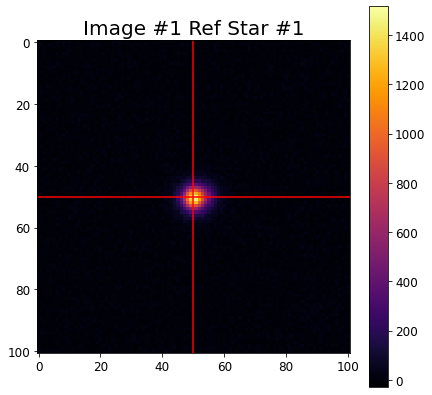

Original Centroid [-0.19781492 -0.82894959]
New Centroid [-0.1997593   0.10188955]


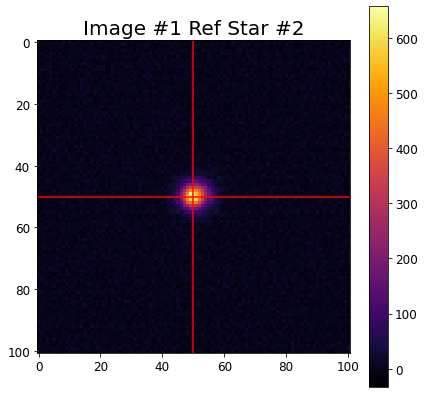

Original Centroid [1.63594298 1.33797018]
New Centroid [-0.3575414   0.34168478]


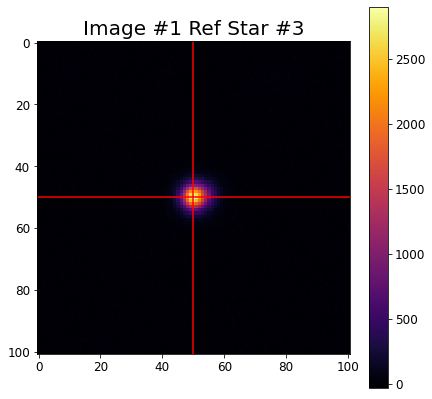

In [7]:
#Repeating the code from above
boxsize = 50

for i, f in enumerate(img_files[:1]):
    
    data, header  = ta.read_file(f)
    w = WCS(header)
    
    for j, star in enumerate(ta.ref_stars):
        
        
        ref_pos = skycoord_to_pixel(star, w)
        ref_x, ref_y = ref_pos
        ref_x_int, ref_y_int = ref_x.astype(int), ref_y.astype(int)
        sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, 
                      ref_x_int-boxsize: ref_x_int+boxsize+1]
        
        #I wrote a function to compute the centroid relative to the center of the sub image
        centroid = ta.centroid(sub_im)
        print("Original Centroid", centroid)
        
        #Notice that the centroid is not at a pixel interval,
        #we should be fine shifting the image as best we can
        sub_im = ta.center_image(data, sub_im, ref_pos)
        new_centroid = ta.centroid(sub_im)
        print("New Centroid", new_centroid)
        
        plt.figure(figsize=(7,7))
        plt.imshow(sub_im, cmap = 'inferno',interpolation = "None")
        plt.title(f"Image #{i+1} Ref Star #{j+1}", size = 20)
        plt.axvline(x = sub_im.shape[0]//2, color = 'red')
        plt.axhline(y = sub_im.shape[0]//2, color = 'red')
        plt.colorbar()
        plt.show()
    

### Now we should be all set to take flux measurements

In [8]:
try: 
    fluxes, flux_errs = np.load("tmp_fluxes.npy"), np.load("tmp_fluxes_err.npy")
except:
    #Repeating the code from above
    boxsize = 50

    sub_im = data[100-boxsize: 100+boxsize+1, 100-boxsize: 100+boxsize+1]

    #Create an aperture and annulus model
    aperture = ta.get_aperture(sub_im.shape, 12)
    annulus = ta.get_annulus(sub_im.shape, 20, 40)

    fluxes = np.empty((len(ta.ref_stars),len(img_files)))
    flux_errs = np.empty_like(fluxes)


    for i, f in enumerate(img_files):
        
        data, header  = ta.read_file(f)
        w = WCS(header)
        
        for j, star in enumerate(ta.ref_stars):
            
            
            ref_pos = skycoord_to_pixel(star, w)
            ref_x, ref_y = ref_pos
            ref_x_int, ref_y_int = ref_x.astype(int), ref_y.astype(int)
            sub_im = data[ref_y_int-boxsize: ref_y_int+boxsize+1, 
                        ref_x_int-boxsize: ref_x_int+boxsize+1]
            sub_im = ta.center_image(data, sub_im, ref_pos)
            
            #Get the flux for each of the reference stars 
            fluxes[j,i], flux_errs[j,i]  = ta.get_flux(sub_im, aperture, annulus, gain = 4)
            
    np.save("tmp_fluxes", fluxes)
    np.save("tmp_fluxes_err", flux_errs)

I have used this source for computing the error in my fluxes: https://wise2.ipac.caltech.edu/staff/fmasci/ApPhotUncert.pdf

For my implementation, I get the following formula:

$$\Delta F = \sqrt{\frac{F}{g} + N_{aperture}\left(1 + \frac{\pi}{2}\frac{N_{aperture}}{N_{annulus}}\right)\sigma_{bg}}$$

Where here I have assumed that read noise is negligeable and that there are no large pixel-to-pixel correlations in the image.

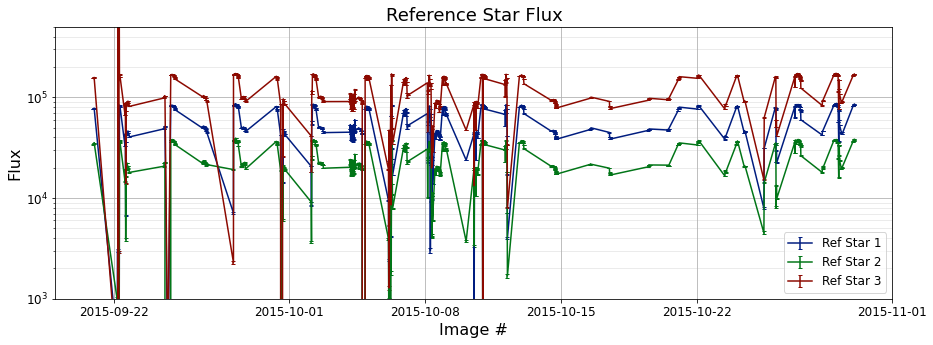

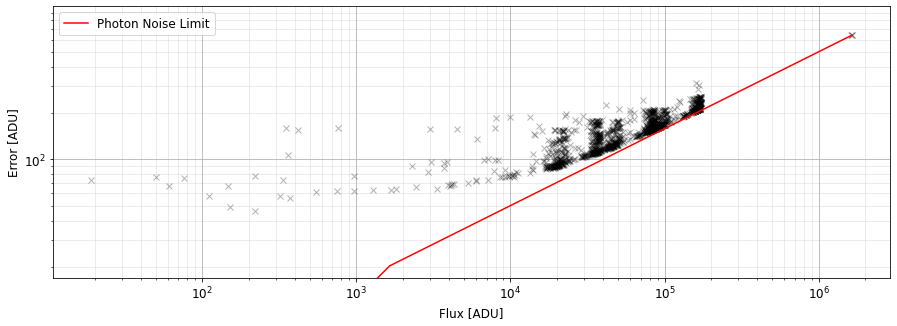

In [11]:
plt.figure(figsize = (15, 5))
xvals = file_times#np.arange(fluxes.shape[1])
for i in range(len(ta.ref_stars)): 
    plt.errorbar(xvals, fluxes[i,:], yerr=flux_errs[i,:], label = f'Ref Star {i+1}', capsize=2, fmt = '-')
plt.yscale('log')
plt.xlabel('Image #', size = 16)
plt.ylabel("Flux", size = 16)
plt.title("Reference Star Flux", size = 18)
plt.ylim(1e3, 5e5)
plt.legend()
plt.grid(which = 'major', alpha = 1)
plt.grid(which = 'minor', alpha = 0.3)
plt.show()

GAIN = 4
plt.figure(figsize = (15, 5))
plt.plot(fluxes.flatten(), flux_errs.flatten(), 'x', color = 'k', alpha = 0.3)
xvals = np.linspace(0, np.max(fluxes), 1000)
plt.plot(xvals, np.sqrt(xvals/GAIN), color = 'r', label = 'Photon Noise Limit')
plt.xscale('log')
plt.yscale('log')
plt.ylabel('Error [ADU]')
plt.xlabel("Flux [ADU]")
plt.legend()
plt.grid(which = 'major', alpha = 1)
plt.grid(which = 'minor', alpha = 0.3)
plt.show()


# Brainstorming and Class discussion


## How can we use the flux data to find bad images?
## What other information can we get from these curves?
## What do we need to do next?

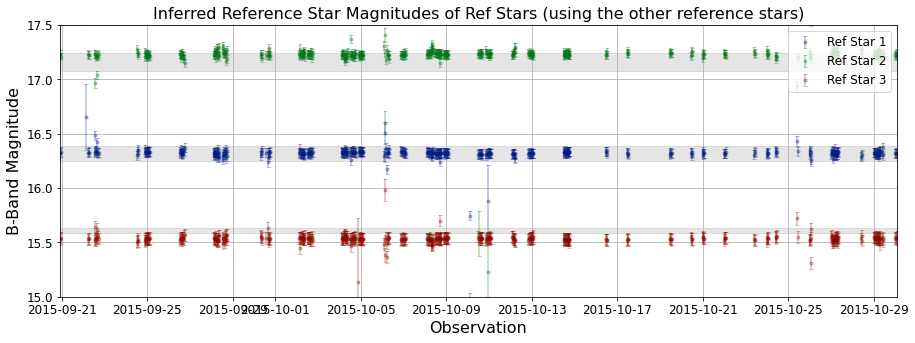

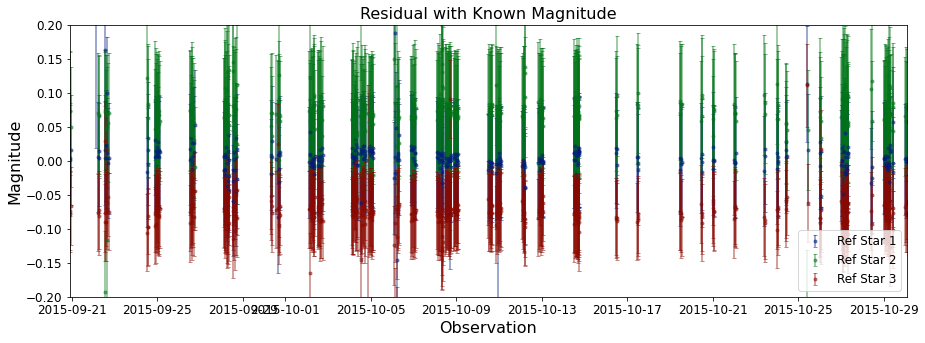

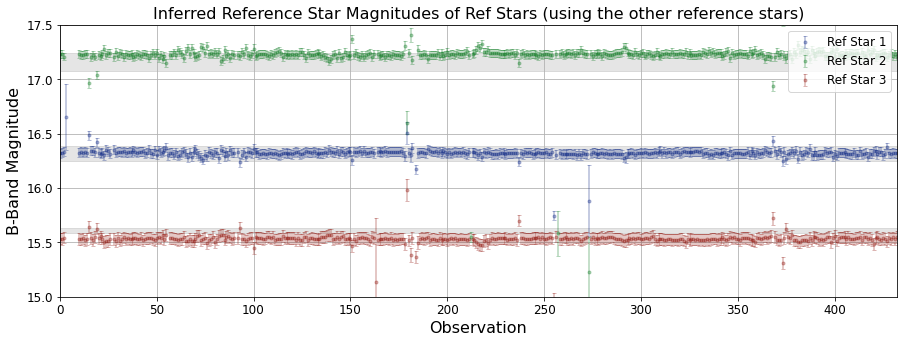

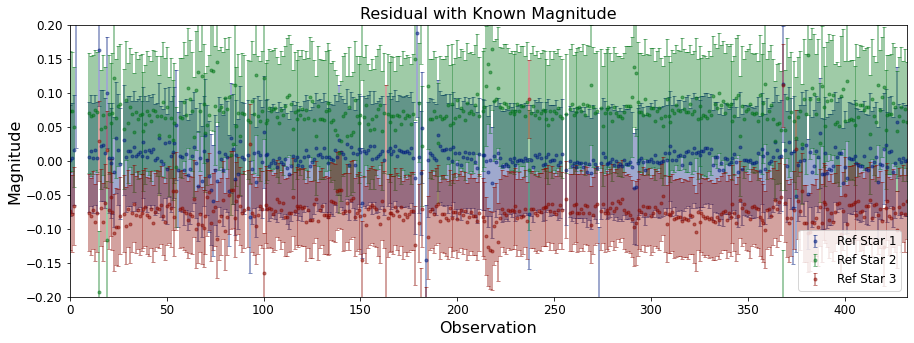

In [10]:

ta.do_stuff(fluxes, flux_errs, xvals = file_times)
ta.do_stuff(fluxes, flux_errs)